Executing Results and Discussion Experiments...


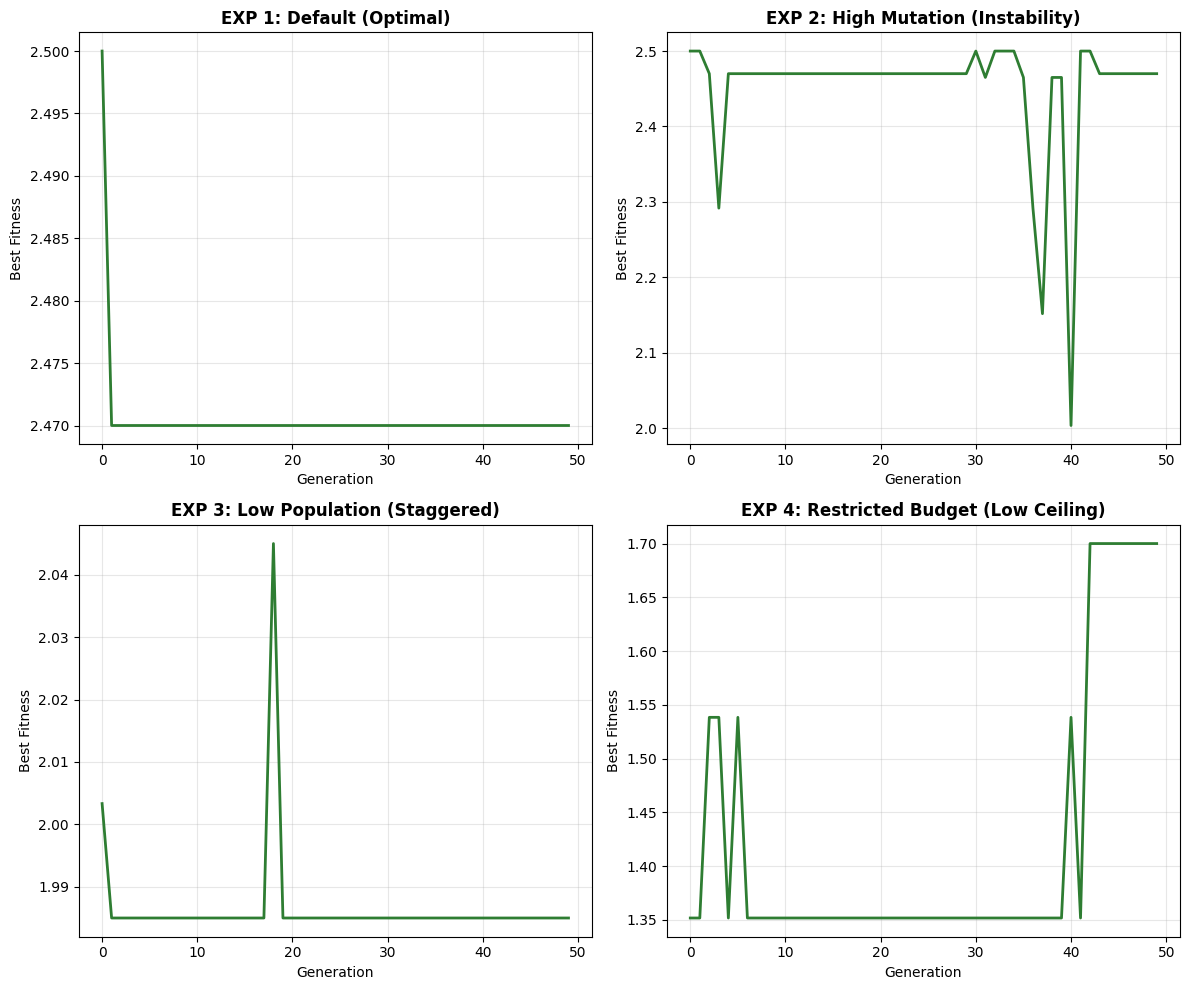

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

# --- DATA SETUP ---
SUPPLEMENT_NAMES = ["Prenatal Basic", "Calcium + Folic", "High Iron", "High Folic", "Daily Balance"]

# Inventory: [Iron (mg), Folic Acid (mcg), Calcium (mg), Cost (RM)]
SUPPLEMENT_INVENTORY = np.array([
    [18, 400, 0, 1.50], [0, 200, 500, 2.00], [27, 0, 0, 1.20],
    [0, 600, 0, 0.80], [9, 100, 250, 1.10],
])

TARGET_RDI = np.array([27, 600, 500])

def calculate_fitness(chromosome, budget, constraints):
    """
    Step 2: FITNESS EVALUATION
    Objective Function: f(x) = (w1*A) - (w2*P) - (w3*C)
    """
    # Hard Constraint Check
    for i in range(len(constraints)):
        if constraints[i] == 1 and chromosome[i] == 0: return 0.0001
        if constraints[i] == 0 and chromosome[i] == 1: return 0.0001

    selected_data = SUPPLEMENT_INVENTORY[chromosome == 1]
    if len(selected_data) == 0: return 0.0001

    totals = np.sum(selected_data, axis=0)
    # EXP 4: Budget Constraint Enforcement
    if totals[3] > budget: return 0.0001

    accuracy = np.sum(np.minimum(totals[:3], TARGET_RDI) / TARGET_RDI)
    pill_penalty = np.sum(chromosome) * 0.1
    cost_penalty = totals[3] * 0.05

    return max(0.0001, accuracy - pill_penalty - cost_penalty)

def run_ga(mutation_rate, pop_size, budget, generations=50):
    """
    Core GA Loop for Experimental Comparisons.
    """
    # Step 1: Initialization
    population = np.random.randint(2, size=(pop_size, len(SUPPLEMENT_INVENTORY)))
    history = []
    no_constraints = [-1] * len(SUPPLEMENT_INVENTORY)

    for gen in range(generations):
        # Step 2: Evaluation
        scores = np.array([calculate_fitness(ind, budget, no_constraints) for ind in population])
        history.append(np.max(scores))

        # Step 3: Selection
        if np.sum(scores) < 1e-6:
            population = np.random.randint(2, size=(pop_size, len(SUPPLEMENT_INVENTORY)))
            continue
        parents = population[np.random.choice(pop_size, size=pop_size, p=scores/np.sum(scores))]

        # Step 4: Crossover
        offspring = []
        for i in range(0, pop_size, 2):
            p1, p2 = parents[i], parents[(i+1)%pop_size]
            cp = random.randint(1, len(SUPPLEMENT_INVENTORY)-1)
            offspring.append(np.concatenate([p1[:cp], p2[cp:]]))
            offspring.append(np.concatenate([p2[:cp], p1[cp:]]))

        # Step 5 & 6: Mutation and Replacement
        population = np.array(offspring)[:pop_size]
        for i in range(pop_size):
            if random.random() < mutation_rate:
                idx = random.randint(0, len(SUPPLEMENT_INVENTORY)-1)
                population[i][idx] = 1 - population[i][idx]

    return history

def run_comparative_experiments():
    """
    Generates Results for Discussion as defined in the Case Study Table.
    """
    exps = [
        (0.1, 20, 5.0, "EXP 1: Default (Optimal)"),
        (0.5, 20, 5.0, "EXP 2: High Mutation (Instability)"),
        (0.1, 5, 5.0, "EXP 3: Low Population (Staggered)"),
        (0.1, 20, 2.5, "EXP 4: Restricted Budget (Low Ceiling)")
    ]

    plt.figure(figsize=(12, 10))
    for i, (m, p, b, title) in enumerate(exps):
        plt.subplot(2, 2, i+1)
        data = run_ga(m, p, b)
        plt.plot(data, color='#2E7D32', linewidth=2)
        plt.title(title, fontweight='bold')
        plt.ylabel('Best Fitness')
        plt.xlabel('Generation')
        plt.grid(True, alpha=0.3)
        plt.annotate(f'Final: {data[-1]:.2f}', xy=(35, data[-1]+0.1), color='red')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("Executing Results and Discussion Experiments...")
    run_comparative_experiments()